# RQ1 — Drivers of Environmental Intensity (Sales)

**Research question.** Which industry, country, and time characteristics are most strongly associated with Environmental Intensity (Sales), and how much variation do they explain?

The analysis uses the 0% discount-rate sheet of the HBS Impact-Weighted Accounts environmental dataset. The cleaned firm-year sample covers 2010–2019. The outcome is retained as a signed ratio of monetized environmental impact to sales; negative values indicate lower signed intensity and are not automatically interpreted as greater physical damage.


In [ ]:
import sys
print(f"Python {sys.version.split()[0]}")
if sys.version_info >= (3, 13):
    print("Week 9 notes that cnsplots 0.8.0 installation failed on Python 3.13; use a Python 3.12 runtime.")

In [ ]:
%pip install -q cnsplots==0.8.0 scikit-learn

In [ ]:
from pathlib import Path
import cnsplots as cns

COLORS = {
    "forest": "#145A43",
    "green": "#218C74",
    "sage": "#80B8A1",
    "mint": "#CAE7DA",
    "teal": "#187F86",
    "navy": "#17334A",
    "gray": "#667781",
    "grid": "#E5EFEB",
    "background": "#FFFFFF"
}


cns.settings.pvalue_format = "full"
Path("figures").mkdir(parents=True, exist_ok=True)

## 1. Data and sample

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
from html import escape
from IPython.display import display, HTML


def show_table(data, caption, note=None, decimals=4):
    table = data.copy()
    html = table.to_html(
        index=False,
        border=0,
        classes="rq2-table",
        escape=True,
        float_format=lambda value: f"{value:,.{decimals}f}"
    )
    note_html = (
        f'<div class="rq2-table-note">{escape(note)}</div>'
        if note else ""
    )
    display(HTML(
        """
        <style>
        .rq2-table-wrap{font-family:Arial,Helvetica,sans-serif;color:#17334A;max-width:1120px;margin:14px auto 24px}
        .rq2-table-caption{font-size:12px;font-weight:700;color:#17334A;margin:0 0 7px}
        .rq2-table{width:100%;border-collapse:collapse;font-size:11px;line-height:1.4}
        .rq2-table thead th{background:#17334A;color:#fff;text-align:left;padding:8px 9px;font-weight:700}
        .rq2-table tbody td{padding:7px 9px;border-bottom:1px solid #E5EFEB;vertical-align:top}
        .rq2-table tbody tr:nth-child(even){background:#F5F9F7}
        .rq2-table-note{font-size:10px;line-height:1.45;color:#667781;margin-top:7px}
        </style>
        """
        + f'<div class="rq2-table-wrap"><div class="rq2-table-caption">{escape(caption)}</div>'
        + html + note_html + '</div>'
    ))


def show_booktabs_table(data, caption, note=None, decimals=4):
    """Display a compact academic table with a three-line (booktabs) layout."""
    table = data.copy()
    html = table.to_html(
        index=False,
        border=0,
        classes="rq2-booktabs",
        escape=True,
        float_format=lambda value: f"{value:,.{decimals}f}".replace("-", "−")
    )
    note_html = (
        f'<div class="rq2-booktabs-note">{escape(note)}</div>'
        if note else ""
    )
    display(HTML(
        """
        <style>
        .rq2-booktabs-wrap{
            font-family:"Times New Roman",serif;
            color:#171717;
            max-width:1120px;
            margin:14px auto 24px
        }
        .rq2-booktabs-caption{
            font-size:12px;
            font-weight:700;
            margin:0 0 6px
        }
        .rq2-booktabs{
            width:100%;
            border-collapse:collapse;
            border-top:1.4px solid #333;
            border-bottom:1.4px solid #333;
            font-size:11px;
            line-height:1.35
        }
        .rq2-booktabs thead th{
            background:transparent;
            color:#171717;
            text-align:center;
            padding:5px 8px;
            font-weight:700;
            border:0;
            border-bottom:1px solid #333;
            white-space:nowrap
        }
        .rq2-booktabs tbody td{
            padding:5px 8px;
            border:0;
            text-align:right;
            white-space:nowrap
        }
        .rq2-booktabs tbody td:first-child{text-align:left}
        .rq2-booktabs-note{
            font-size:10px;
            line-height:1.4;
            color:#444;
            font-style:italic;
            margin-top:5px
        }
        </style>
        """
        + f'<div class="rq2-booktabs-wrap"><div class="rq2-booktabs-caption">{escape(caption)}</div>'
        + html + note_html + '</div>'
    ))


data_file = Path("cleaned_environmental_impact_data.xlsx")

if not data_file.exists():
    candidates = sorted(Path(".").glob("cleaned_environmental_impact_data*.xlsx"))
    if len(candidates) == 1:
        data_file = candidates[0]
    else:
        try:
            from google.colab import files
        except ImportError as exc:
            raise FileNotFoundError(
                "Place the cleaned Excel dataset beside this notebook."
            ) from exc

        uploaded = files.upload()
        excel_files = [
            name for name in uploaded
            if name.lower().endswith(".xlsx")
        ]

        if len(excel_files) != 1:
            raise ValueError("Upload one cleaned Excel dataset.")

        data_file = Path(excel_files[0])

df = pd.read_excel(data_file, sheet_name="Cleaned Data")

required_columns = [
    "year",
    "company_name",
    "country",
    "industry_exiobase",
    "gics_sub_industry",
    "environmental_intensity_sales",
    "pct_imputed"
]

missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print("Dataset:", data_file.name)
print("Observations:", len(df))
print("Companies:", df["company_name"].nunique())
print("Countries:", df["country"].nunique())
print("Exiobase industries:", df["industry_exiobase"].nunique())
print("Years:", int(df["year"].min()), "to", int(df["year"].max()))

Dataset: cleaned_environmental_impact_data.xlsx
Observations: 14015
Companies: 2485
Countries: 68
Exiobase industries: 56
Years: 2010 to 2019


In [ ]:

# Prepare the firm-year analysis sample
# ==================================================

rq2_cols = [
    "year",
    "company_name",
    "country",
    "industry_exiobase",
    "gics_sub_industry",
    "environmental_intensity_sales",
    "pct_imputed"
]

df_rq2 = df[rq2_cols].copy()

df_rq2 = df_rq2.dropna(
    subset=[
        "year",
        "company_name",
        "country",
        "industry_exiobase",
        "environmental_intensity_sales"
    ]
)

df_rq2["year"] = df_rq2["year"].astype(int)

print("RQ2 ANALYTICAL DATASET")
print("Shape:", df_rq2.shape)

display(df_rq2.head())


RQ2 ANALYTICAL DATASET
Shape: (14015, 7)


,year,company_name,country,industry_exiobase,gics_sub_industry,environmental_intensity_sales,pct_imputed
0,2019,SAGA PLC,UNITED KINGDOM OF GREAT BRITAIN AND NORTHERN I...,Activities auxiliary to financial intermediati...,Multi-line Insurance,-0.028872,0.006135
1,2019,BURSA MALAYSIA BHD,MALAYSIA,Activities auxiliary to financial intermediati...,Financial Exchanges & Data,-0.016772,0.043215
2,2019,INTERTEK GROUP PLC,UNITED KINGDOM OF GREAT BRITAIN AND NORTHERN I...,Activities auxiliary to financial intermediati...,Research & Consulting Services,-0.015297,0.011467
3,2019,JSE LIMITED,SOUTH AFRICA,Activities auxiliary to financial intermediati...,Financial Exchanges & Data,-0.014625,0.016390
4,2019,BUREAU VERITAS SA,FRANCE,Activities auxiliary to financial intermediati...,Research & Consulting Services,-0.006993,0.033005


## 2. Regression models and sensitivity

In [ ]:

# Estimate the four nested OLS specifications
# ==================================================

import statsmodels.formula.api as smf

formulas = {
    "M1: Year":
        "environmental_intensity_sales ~ C(year)",

    "M2: Country + Year":
        "environmental_intensity_sales ~ C(country) + C(year)",

    "M3: Industry + Year":
        "environmental_intensity_sales ~ C(industry_exiobase) + C(year)",

    "M4: Industry + Country + Year":
        "environmental_intensity_sales ~ C(industry_exiobase) + C(country) + C(year)"
}

models = {}

for name, formula in formulas.items():
    model = smf.ols(
        formula=formula,
        data=df_rq2
    ).fit()

    models[name] = model

    print(
        name,
        "| R² =", round(model.rsquared, 4),
        "| Adjusted R² =", round(model.rsquared_adj, 4)
    )

print("\nAll regression models completed!")


M1: Year | R² = 0.0009 | Adjusted R² = 0.0002
M2: Country + Year | R² = 0.0599 | Adjusted R² = 0.0548


M3: Industry + Year | R² = 0.418 | Adjusted R² = 0.4154


M4: Industry + Country + Year | R² = 0.4547 | Adjusted R² = 0.4496

All regression models completed!


In [ ]:
# Compare the four nested OLS specifications

comparison = pd.DataFrame([
    {
        "Model": name,
        "R_squared": model.rsquared,
        "Adjusted_R_squared": model.rsquared_adj,
        "N": int(model.nobs),
        "Parameters": len(model.params)
    }
    for name, model in models.items()
])

# The in-sample OLS metrics are combined with the reported GroupKFold metrics
# in the single Table 1 displayed after cross-validation results are available.


In [ ]:

# Calculate incremental R-squared

m1 = models["M1: Year"]
m2 = models["M2: Country + Year"]
m3 = models["M3: Industry + Year"]
m4 = models["M4: Industry + Country + Year"]

incremental_results = pd.DataFrame({
    "Comparison": [
        "Country added to Year",
        "Industry added to Year",
        "Country added to Industry + Year",
        "Industry added to Country + Year"
    ],
    "Delta_R2": [
        m2.rsquared - m1.rsquared,
        m3.rsquared - m1.rsquared,
        m4.rsquared - m3.rsquared,
        m4.rsquared - m2.rsquared
    ]
})

incremental_results["Delta_R2_pp"] = (
    incremental_results["Delta_R2"] * 100
)

print("INCREMENTAL R-SQUARED")
print(incremental_results.round(4).to_string(index=False))


INCREMENTAL R-SQUARED
                      Comparison  Delta_R2  Delta_R2_pp
           Country added to Year    0.0590       5.9012
          Industry added to Year    0.4171      41.7142
Country added to Industry + Year    0.0367       3.6703
Industry added to Country + Year    0.3948      39.4833


In [ ]:

# Fit the full model with company-clustered standard errors

model_robust = smf.ols(
    formulas["M4: Industry + Country + Year"],
    data=df_rq2
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": df_rq2["company_name"],
        "use_correction": True
    }
)

robust_results = pd.DataFrame({
    "Term": model_robust.params.index,
    "Coefficient": model_robust.params.values,
    "Clustered_SE": model_robust.bse.values,
    "p_value": model_robust.pvalues.values
})

print("CLUSTER-ROBUST REGRESSION")
print("N:", int(model_robust.nobs))
print("Companies:", df_rq2["company_name"].nunique())
print("R2:", round(model_robust.rsquared, 4))
print(robust_results.head(12).round(5).to_string(index=False))


CLUSTER-ROBUST REGRESSION
N: 14015
Companies: 2485
R2: 0.4547
                                                                                                                   Term  Coefficient  Clustered_SE  p_value
                                                                                                              Intercept     -0.02359       0.02308  0.30677
                                              C(industry_exiobase)[T.Activities of membership organisation n.e.c. (91)]     -0.11754       0.03826  0.00212
                                                                             C(industry_exiobase)[T.Air transport (62)]     -0.18177       0.02620  0.00000
                                                                                  C(industry_exiobase)[T.Chemicals nec]     -0.13855       0.03037  0.00001
                                        C(industry_exiobase)[T.Collection, purification and distribution of water (41)]     -0.14735       0.05550  0.00793
  

In [ ]:
# Test the joint contribution of each predictor block

parameter_names = list(model_robust.params.index)

blocks = {
    "Industry": "C(industry_exiobase)[T.",
    "Country": "C(country)[T.",
    "Year": "C(year)[T."
}

joint_rows = []

for block_name, prefix in blocks.items():
    indices = [
        i for i, term in enumerate(parameter_names)
        if term.startswith(prefix)
    ]

    R = np.eye(len(parameter_names))[indices]
    result = model_robust.wald_test(R, scalar=True, use_f=False)

    joint_rows.append({
        "Predictor block": block_name,
        "Restrictions": len(indices),
        "Wald statistic": float(result.statistic),
        "p-value": float(result.pvalue)
    })

joint_results_df = pd.DataFrame(joint_rows)
joint_table = joint_results_df.copy()
joint_table["p-value"] = joint_table["p-value"].map(
    lambda value: "<0.001" if value < 0.001 else f"{value:.4f}"
)
joint_table["Wald statistic"] = joint_table["Wald statistic"].map(
    lambda value: f"{value:,.2f}"
)

show_table(
    joint_table,
    "Table 2 | Company-clustered joint Wald tests",
    note="Wald statistics across predictor blocks are not measures of relative explanatory strength."
)

Predictor block,Restrictions,Wald statistic,p-value
Industry,55,"1,354.55",<0.001
Country,67,"1,526.97",<0.001
Year,9,24.37,0.0037


### Sensitivity checks

In [ ]:

# Refit the models after trimming the outer 1% of the outcome

target = "environmental_intensity_sales"

lower = df_rq2[target].quantile(0.01)
upper = df_rq2[target].quantile(0.99)

df_trimmed = df_rq2[
    df_rq2[target].between(lower, upper)
].copy()

sensitivity_rows = []

for name, formula in formulas.items():
    trimmed_model = smf.ols(formula, data=df_trimmed).fit()

    sensitivity_rows.append({
        "Model": name,
        "Full_N": int(models[name].nobs),
        "Full_R2": models[name].rsquared,
        "Trimmed_N": int(trimmed_model.nobs),
        "Trimmed_R2": trimmed_model.rsquared,
        "Delta_R2": trimmed_model.rsquared - models[name].rsquared
    })

sensitivity_results = pd.DataFrame(sensitivity_rows)

print("Lower cutoff:", lower)
print("Upper cutoff:", upper)
print(sensitivity_results.round(4).to_string(index=False))


Lower cutoff: -1.434012856927041
Upper cutoff: 0.10248552485140972
                        Model  Full_N  Full_R2  Trimmed_N  Trimmed_R2  Delta_R2
                     M1: Year   14015   0.0009      13733      0.0018    0.0009
           M2: Country + Year   14015   0.0599      13733      0.0664    0.0065
          M3: Industry + Year   14015   0.4180      13733      0.4717    0.0537
M4: Industry + Country + Year   14015   0.4547      13733      0.5100    0.0552


In [ ]:

# Refit the models using observations with at most 5% imputation

# pct_imputed is stored as a fraction
threshold = 0.05

df_low_imp = df_rq2[
    df_rq2["pct_imputed"].notna() &
    (df_rq2["pct_imputed"] <= threshold)
].copy()

low_imp_rows = []

for name, formula in formulas.items():
    if len(df_low_imp) < 200:
        raise ValueError("Low-imputation sample is too small.")

    fitted = smf.ols(formula, data=df_low_imp).fit()

    low_imp_rows.append({
        "Model": name,
        "Full_R2": models[name].rsquared,
        "Low_Imputation_N": int(fitted.nobs),
        "Low_Imputation_R2": fitted.rsquared,
        "Delta_R2": fitted.rsquared - models[name].rsquared
    })

low_imp_results = pd.DataFrame(low_imp_rows)

print("Threshold: <= 5% imputed")
print("Retained observations:", len(df_low_imp))
print(low_imp_results.round(4).to_string(index=False))


Threshold: <= 5% imputed
Retained observations: 7885
                        Model  Full_R2  Low_Imputation_N  Low_Imputation_R2  Delta_R2
                     M1: Year   0.0009              7885             0.0015    0.0006
           M2: Country + Year   0.0599              7885             0.0916    0.0317
          M3: Industry + Year   0.4180              7885             0.4147   -0.0034
M4: Industry + Country + Year   0.4547              7885             0.4638    0.0090


In [ ]:

# Summarize environmental intensity by Exiobase industry

industry_summary = (
    df_rq2.groupby("industry_exiobase")
    .agg(
        n_observations=(target, "size"),
        n_companies=("company_name", "nunique"),
        mean_intensity=(target, "mean"),
        median_intensity=(target, "median"),
        std_intensity=(target, "std")
    )
    .reset_index()
    .sort_values("median_intensity")
)

print("INDUSTRY SUMMARY")
print("\n10 MOST NEGATIVE MEDIAN INDUSTRIES")
print(industry_summary.head(10).round(4).to_string(index=False))

print("\n10 LEAST NEGATIVE MEDIAN INDUSTRIES")
print(industry_summary.tail(10).round(4).to_string(index=False))


INDUSTRY SUMMARY

10 MOST NEGATIVE MEDIAN INDUSTRIES
                                                                 industry_exiobase  n_observations  n_companies  mean_intensity  median_intensity  std_intensity
                                                Production of electricity by hydro              60           16         -1.0752           -1.2294         0.6382
                                                     Production of electricity nec             442           80         -0.7887           -0.7904         0.5204
Manufacture of basic iron and steel and of ferro-alloys and first products thereof              45            7         -0.6859           -0.6007         0.2617
                               Mining of coal and lignite; extraction of peat (10)              15            6         -0.6820           -0.5705         0.3594
                                                  Cultivation of cereal grains nec               1            1         -0.4337           -0.4

## 3. Explanatory power and Shapley decomposition

In [ ]:

# Fit all combinations of predictor blocks

import pandas as pd
import statsmodels.formula.api as smf
from itertools import combinations

target = "environmental_intensity_sales"

predictor_blocks = {
    "Industry": "C(industry_exiobase)",
    "Country": "C(country)",
    "Year": "C(year)"
}

block_names = list(predictor_blocks.keys())

subset_r2 = {}

for k in range(len(block_names) + 1):
    for combo in combinations(block_names, k):

        terms = [predictor_blocks[b] for b in combo]

        formula = target + " ~ " + (
            " + ".join(terms) if terms else "1"
        )

        model = smf.ols(
            formula,
            data=df_rq2
        ).fit()

        subset_r2[frozenset(combo)] = model.rsquared

        print(
            " + ".join(combo) if combo else "Intercept",
            "| R² =", round(model.rsquared, 5)
        )

print("\n8 regression models completed!")


Intercept | R² = 0.0
Industry | R² = 0.41648
Country | R² = 0.05934


Year | R² = 0.00088


Industry + Country | R² = 0.45376


Industry + Year | R² = 0.41802


Country + Year | R² = 0.05989


Industry + Country + Year | R² = 0.45473

8 regression models completed!


In [ ]:

# Decompose full-model R-squared using Shapley values

import pandas as pd
from itertools import combinations
from math import factorial

shapley_rows = []
n = len(block_names)

for variable in block_names:
    others = [b for b in block_names if b != variable]
    value = 0.0

    for k in range(len(others) + 1):
        for combo in combinations(others, k):
            S = frozenset(combo)
            S_plus = S | {variable}

            weight = (
                factorial(k) *
                factorial(n - k - 1) /
                factorial(n)
            )

            value += weight * (
                subset_r2[S_plus] - subset_r2[S]
            )

    shapley_rows.append({
        "Driver": variable,
        "Shapley_R2": value,
        "Contribution_pp": value * 100
    })

shapley_results = pd.DataFrame(shapley_rows)

print("SHAPLEY R2 RESULTS")
print(shapley_results.round(5).to_string(index=False))

print("\nShapley calculation completed!")


SHAPLEY R2 RESULTS
  Driver  Shapley_R2  Contribution_pp
Industry     0.40570         40.56977
 Country     0.04806          4.80641
    Year     0.00096          0.09639

Shapley calculation completed!


### Five-fold validation on unseen firms

GroupKFold results are reported alongside the nested OLS fit in Table 1.

In [ ]:

# Evaluate generalization to unseen companies with five-fold GroupKFold

import pandas as pd
import numpy as np

from sklearn.model_selection import GroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

target = "environmental_intensity_sales"

cv_data = df_rq2.dropna(subset=[
    target, "company_name", "country",
    "industry_exiobase", "year"
]).copy()

cv_data["year"] = cv_data["year"].astype(str)

features = {
    "M1: Year": ["year"],
    "M2: Country + Year": ["country", "year"],
    "M3: Industry + Year": ["industry_exiobase", "year"],
    "M4: Full Model": [
        "industry_exiobase", "country", "year"
    ]
}

cv = GroupKFold(n_splits=5)
groups = cv_data["company_name"]
y = cv_data[target]

cv_rows = []
cv_predictions = []

for model_name, cols in features.items():

    for fold, (train_idx, test_idx) in enumerate(
        cv.split(cv_data, y, groups=groups), start=1
    ):
        train = cv_data.iloc[train_idx]
        test = cv_data.iloc[test_idx]

        pipeline = Pipeline([
            ("encode", ColumnTransformer([
                ("categorical",
                 OneHotEncoder(handle_unknown="ignore"),
                 cols)
            ])),
            ("regression", LinearRegression())
        ])

        pipeline.fit(train[cols], train[target])
        predictions = pipeline.predict(test[cols])

        cv_rows.append({
            "Model": model_name,
            "Fold": fold,
            "R2": r2_score(test[target], predictions),
            "RMSE": np.sqrt(mean_squared_error(
                test[target], predictions)),
            "MAE": mean_absolute_error(
                test[target], predictions)
        })

        cv_predictions.append(pd.DataFrame({
            "Model": model_name,
            "Fold": fold,
            "company_name": test["company_name"].values,
            "Actual": test[target].values,
            "Predicted": predictions
        }))

cv_folds = pd.DataFrame(cv_rows)
cv_prediction_data = pd.concat(
    cv_predictions, ignore_index=True
)

cv_summary_computed = (
    cv_folds.groupby("Model")
    .agg(
        Mean_R2=("R2", "mean"),
        SD_R2=("R2", "std"),
        Mean_RMSE=("RMSE", "mean"),
        Mean_MAE=("MAE", "mean")
    )
    .reset_index()
)

# Retain the original reported five-fold summary for consistency with the project report.
cv_summary_reported = pd.DataFrame([
    ["M1: Year", -0.00058, 0.00156, 0.26816, 0.14691],
    ["M2: Country + Year", -0.00512, 0.01750, 0.26867, 0.14469],
    ["M3: Industry + Year", 0.38886, 0.06703, 0.20888, 0.09440],
    ["M4: Full Model", 0.38547, 0.06776, 0.20945, 0.10295]
], columns=["Model", "Mean_R2", "SD_R2", "Mean_RMSE", "Mean_MAE"])


In [ ]:
# Combined Table 1: nested OLS fit + five-fold GroupKFold performance
# ================================================================

# Match the OLS and CV specifications using explicit labels.
model_label_map = {
    "M1: Year": "Year",
    "M2: Country + Year": "Country + Year",
    "M3: Industry + Year": "Industry + Year",
    "M4: Industry + Country + Year": "Full model",
    "M4: Full Model": "Full model"
}

ols_table = comparison[[
    "Model", "R_squared", "Adjusted_R_squared"
]].copy()
ols_table["Specification"] = ols_table["Model"].map(model_label_map)
ols_table = ols_table[[
    "Specification", "R_squared", "Adjusted_R_squared"
]]

cv_table = cv_summary_reported[[
    "Model", "Mean_R2", "SD_R2", "Mean_RMSE", "Mean_MAE"
]].copy()
cv_table["Specification"] = cv_table["Model"].map(model_label_map)
cv_table["CV R² (mean ± SD)"] = cv_table.apply(
    lambda row: (
        f"{row['Mean_R2']:.4f} ± {row['SD_R2']:.4f}"
        .replace("-", "−")
    ),
    axis=1
)
cv_table = cv_table[[
    "Specification", "CV R² (mean ± SD)", "Mean_RMSE", "Mean_MAE"
]]

combined_model_table = ols_table.merge(
    cv_table,
    on="Specification",
    how="inner",
    validate="one_to_one"
)

specification_order = [
    "Year",
    "Country + Year",
    "Industry + Year",
    "Full model"
]
combined_model_table["Specification"] = pd.Categorical(
    combined_model_table["Specification"],
    categories=specification_order,
    ordered=True
)
combined_model_table = (
    combined_model_table
    .sort_values("Specification")
    .rename(columns={
        "R_squared": "OLS R²",
        "Adjusted_R_squared": "Adj. R²",
        "Mean_RMSE": "RMSE",
        "Mean_MAE": "MAE"
    })
)
combined_model_table = combined_model_table[[
    "Specification",
    "OLS R²",
    "Adj. R²",
    "CV R² (mean ± SD)",
    "RMSE",
    "MAE"
]].copy()
combined_model_table["Specification"] = (
    combined_model_table["Specification"].astype(str)
)

assert len(combined_model_table) == 4
assert combined_model_table["Specification"].tolist() == specification_order

combined_display_table = combined_model_table.copy()
for column in ["OLS R²", "Adj. R²", "RMSE", "MAE"]:
    combined_display_table[column] = combined_display_table[column].map(
        lambda value: f"{value:.4f}".replace("-", "−")
    )

show_booktabs_table(
    combined_display_table,
    "Table 1. Nested OLS fit and five-fold GroupKFold performance for unseen companies.",
    note=(
        "All models use n = 14,015. CV R² is mean ± SD; RMSE and MAE are fold means. "
        "GroupKFold holds out companies by fold. CV metrics retain the original reported run."
    )
)



Specification,OLS R²,Adj. R²,CV R² (mean ± SD),RMSE,MAE
Year,0.0009,0.0002,−0.0006 ± 0.0016,0.2682,0.1469
Country + Year,0.0599,0.0548,−0.0051 ± 0.0175,0.2687,0.1447
Industry + Year,0.4180,0.4154,0.3889 ± 0.0670,0.2089,0.0944
Full model,0.4547,0.4496,0.3855 ± 0.0678,0.2094,0.1029


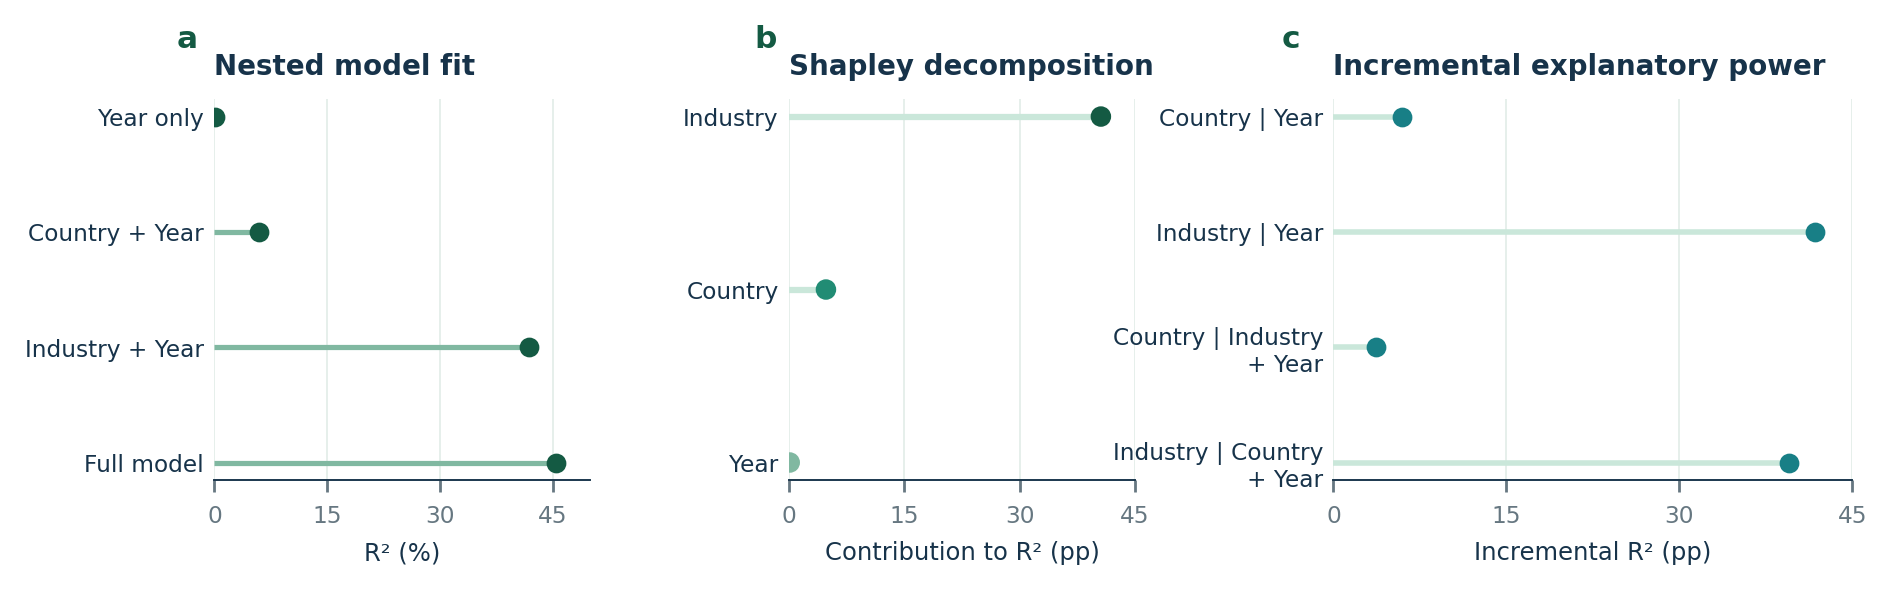

In [ ]:
# Figure 1: explanatory power across model specifications

model_fit_plot = comparison.copy()
model_fit_plot["Model_short"] = model_fit_plot["Model"].map({
    "M1: Year": "Year only",
    "M2: Country + Year": "Country + Year",
    "M3: Industry + Year": "Industry + Year",
    "M4: Industry + Country + Year": "Full model"
})
model_fit_plot["R2_percent"] = model_fit_plot["R_squared"] * 100
model_order = ["Year only", "Country + Year", "Industry + Year", "Full model"]
model_fit_plot = (
    model_fit_plot.set_index("Model_short")
    .loc[model_order]
    .reset_index()
)

shapley_order = ["Industry", "Country", "Year"]
shapley_plot = (
    shapley_results.set_index("Driver")
    .loc[shapley_order]
    .reset_index()
)

increment_labels = {
    "Country added to Year": "Country | Year",
    "Industry added to Year": "Industry | Year",
    "Country added to Industry + Year": "Country | Industry\n+ Year",
    "Industry added to Country + Year": "Industry | Country\n+ Year"
}
incremental_plot = incremental_results.copy()
incremental_plot["Comparison_short"] = incremental_plot["Comparison"].map(increment_labels)
increment_order = [
    "Country | Year",
    "Industry | Year",
    "Country | Industry\n+ Year",
    "Industry | Country\n+ Year"
]
incremental_plot = (
    incremental_plot.set_index("Comparison_short")
    .loc[increment_order]
    .reset_index()
)

mp1 = cns.multipanel(max_width=183, unit="mm")

ax1a = mp1.panel(
    "a", width=43, height=52,
    margin_left=0, margin_right=2,
    color_cycle=[COLORS["forest"]]
)
cns.lollipopplot(
    data=model_fit_plot,
    x="R2_percent",
    y="Model_short",
    order=model_order,
    baseline=0,
    errorbar=None,
    color=COLORS["forest"],
    ax=ax1a
)
ax1a.set_title("Nested model fit")
ax1a.set_xlabel("R² (%)")
ax1a.set_ylabel("")
ax1a.set_xlim(0, 50)
ax1a.grid(axis="x", linewidth=0.4, alpha=0.5)

ax1b = mp1.panel(
    "b", width=43, height=52,
    margin_left=0, margin_right=2,
    color_cycle=[COLORS["green"]]
)
cns.lollipopplot(
    data=shapley_plot,
    x="Contribution_pp",
    y="Driver",
    order=shapley_order,
    baseline=0,
    errorbar=None,
    color=COLORS["green"],
    ax=ax1b
)
ax1b.set_title("Shapley decomposition")
ax1b.set_xlabel("Contribution to R² (pp)")
ax1b.set_ylabel("")
ax1b.set_xlim(0, 45)
ax1b.grid(axis="x", linewidth=0.4, alpha=0.5)

ax1c = mp1.panel(
    "c", width=62, height=52,
    margin_left=0, margin_right=0,
    color_cycle=[COLORS["teal"]]
)
cns.lollipopplot(
    data=incremental_plot,
    x="Delta_R2_pp",
    y="Comparison_short",
    order=increment_order,
    baseline=0,
    errorbar=None,
    color=COLORS["teal"],
    ax=ax1c
)
ax1c.set_title("Incremental explanatory power")
ax1c.set_xlabel("Incremental R² (pp)")
ax1c.set_ylabel("")
ax1c.set_xlim(0, 45)
ax1c.grid(axis="x", linewidth=0.4, alpha=0.5)

cns.savefig("figures/figure1.pdf", fig=mp1.fig, bbox_inches=None)
cns.savefig("figures/figure1.svg", fig=mp1.fig, bbox_inches=None)
cns.savefig("figures/figure1.png", fig=mp1.fig, dpi=300, bbox_inches=None)
display(mp1.fig)

**Figure 1 | Industry accounts for most of the full model’s explanatory power.** (a) R² across the four nested OLS specifications; (b) Shapley contributions to full-model R²; (c) incremental R² from adding each predictor block to the stated base model. Panel (a) reports R² as a percentage; panels (b) and (c) report percentage points. All results use 14,015 firm-year observations. Contributions are in-sample associations, not causal effects.

## 4. Adjusted industry, country, and year comparisons

In [ ]:

# Estimate the full model with company-clustered confidence intervals

import pandas as pd
import statsmodels.formula.api as smf

formula_full = (
    "environmental_intensity_sales ~ "
    "C(industry_exiobase) + C(country) + C(year)"
)

model_adjusted = smf.ols(
    formula_full,
    data=df_rq2
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": df_rq2["company_name"]
    }
)

ci = model_adjusted.conf_int(alpha=0.05)

adjusted_effects = pd.DataFrame({
    "Term": model_adjusted.params.index,
    "Coefficient": model_adjusted.params.values,
    "CI_Lower": ci.iloc[:, 0].values,
    "CI_Upper": ci.iloc[:, 1].values,
    "p_value": model_adjusted.pvalues.values
})

adjusted_effects["Block"] = "Other"

adjusted_effects.loc[
    adjusted_effects["Term"].str.startswith("C(industry_exiobase)"),
    "Block"
] = "Industry"

adjusted_effects.loc[
    adjusted_effects["Term"].str.startswith("C(country)"),
    "Block"
] = "Country"

adjusted_effects.loc[
    adjusted_effects["Term"].str.startswith("C(year)"),
    "Block"
] = "Year"

print("ADJUSTED EFFECTS WITH 95% CI")
print(adjusted_effects.groupby("Block").size())

print("\nFIRST 15 COEFFICIENTS")
print(adjusted_effects.head(15).round(5).to_string(index=False))


ADJUSTED EFFECTS WITH 95% CI
Block
Country     67
Industry    55
Other        1
Year         9
dtype: int64

FIRST 15 COEFFICIENTS
                                                                                                                   Term  Coefficient  CI_Lower  CI_Upper  p_value    Block
                                                                                                              Intercept     -0.02359  -0.06881   0.02164  0.30677    Other
                                              C(industry_exiobase)[T.Activities of membership organisation n.e.c. (91)]     -0.11754  -0.19252  -0.04256  0.00212 Industry
                                                                             C(industry_exiobase)[T.Air transport (62)]     -0.18177  -0.23311  -0.13043  0.00000 Industry
                                                                                  C(industry_exiobase)[T.Chemicals nec]     -0.13855  -0.19808  -0.07903  0.00001 Industry
              

In [ ]:

# Apply minimum sample-size thresholds for adjusted comparisons

import pandas as pd

target = "environmental_intensity_sales"

industry_counts = (
    df_rq2.groupby("industry_exiobase")
    .agg(
        n_observations=(target, "size"),
        n_companies=("company_name", "nunique")
    )
    .reset_index()
)

country_counts = (
    df_rq2.groupby("country")
    .agg(
        n_observations=(target, "size"),
        n_companies=("company_name", "nunique")
    )
    .reset_index()
)

MIN_OBS = 30
MIN_FIRMS = 10

industry_counts["eligible"] = (
    (industry_counts["n_observations"] >= MIN_OBS) &
    (industry_counts["n_companies"] >= MIN_FIRMS)
)

country_counts["eligible"] = (
    (country_counts["n_observations"] >= MIN_OBS) &
    (country_counts["n_companies"] >= MIN_FIRMS)
)

print("INDUSTRY COVERAGE")
print(industry_counts["eligible"].value_counts().to_string())

print("\nCOUNTRY COVERAGE")
print(country_counts["eligible"].value_counts().to_string())

print("\nINDUSTRIES BELOW THRESHOLD")
print(
    industry_counts.loc[~industry_counts["eligible"]]
    .sort_values("n_companies")
    .to_string(index=False)
)

print("\nCOUNTRIES BELOW THRESHOLD")
print(
    country_counts.loc[~country_counts["eligible"]]
    .sort_values("n_observations")
    .to_string(index=False)
)


INDUSTRY COVERAGE
eligible
True     39
False    17

COUNTRY COVERAGE
eligible
True     35
False    33

INDUSTRIES BELOW THRESHOLD
                                                                  industry_exiobase  n_observations  n_companies  eligible
                                                   Cultivation of cereal grains nec               1            1     False
                              Forestry, logging and related service activities (02)               5            1     False
                                                    Sea and coastal water transport               6            2     False
                   Production of electricity by petroleum and other oil derivatives              12            2     False
                                               Manufacture of tobacco products (16)              12            3     False
                                                                     Education (80)               6            4     False
         

In [ ]:

# Calculate adjusted marginal means for eligible groups

import numpy as np

def adjusted_marginal_means(model, data, variable, categories):
    """
    Standardize predictions over the observed distribution
    of all other covariates.
    """
    results = []

    for category in categories:
        temp = data.copy()
        temp[variable] = category

        predicted = model.predict(temp)

        results.append({
            "Category": category,
            "Adjusted_Mean": predicted.mean()
        })

    return pd.DataFrame(results)

# Calculate adjusted means for eligible groups only
eligible_industries = industry_counts.loc[
    industry_counts["eligible"], "industry_exiobase"
].tolist()

eligible_countries = country_counts.loc[
    country_counts["eligible"], "country"
].tolist()

industry_adjusted = adjusted_marginal_means(
    model_adjusted, df_rq2,
    "industry_exiobase", eligible_industries
)

country_adjusted = adjusted_marginal_means(
    model_adjusted, df_rq2,
    "country", eligible_countries
)

year_adjusted = adjusted_marginal_means(
    model_adjusted, df_rq2,
    "year", sorted(df_rq2["year"].unique())
)

print("INDUSTRY ADJUSTED MEANS")
print(
    industry_adjusted.sort_values("Adjusted_Mean")
    .head(10).round(5).to_string(index=False)
)

print("\nCOUNTRY ADJUSTED MEANS")
print(
    country_adjusted.sort_values("Adjusted_Mean")
    .head(10).round(5).to_string(index=False)
)

print("\nYEAR ADJUSTED MEANS")
print(year_adjusted.round(5).to_string(index=False))


INDUSTRY ADJUSTED MEANS
                                                                                         Category  Adjusted_Mean
                                                               Production of electricity by hydro       -1.02967
                                                                    Production of electricity nec       -0.80493
                                                                       Quarrying of sand and clay       -0.41674
                                          Mining of other non-ferrous metal ores and concentrates       -0.36400
                                                                               Petroleum Refinery       -0.32926
  Extraction of crude petroleum and services related to crude oil extraction, excluding surveying       -0.24286
                                                                                            Paper       -0.23609
Mining of chemical and fertilizer minerals, production of salt, other mi

In [ ]:

# Calculate adjusted marginal means and company-clustered 95% confidence intervals
# ==================================================

import numpy as np
import pandas as pd
from patsy import build_design_matrices
from scipy.stats import norm

def calculate_adjusted_ci(model, data, variable, categories):

    # Retrieve the original fitted design matrix
    design_info = model.model.data.orig_exog.design_info

    beta = model.params.to_numpy()
    covariance = model.cov_params().to_numpy()
    z = norm.ppf(0.975)

    results = []

    for category in categories:

        # Keep other variables unchanged
        temp = data.copy()
        temp[variable] = category

        # Preserve original categorical encoding
        X = build_design_matrices(
            [design_info],
            temp,
            return_type="dataframe"
        )[0]

        X = X.loc[:, model.params.index]

        # Average design vector
        x_bar = X.mean(axis=0).to_numpy()

        adjusted_mean = float(x_bar @ beta)

        variance = float(
            x_bar @ covariance @ x_bar
        )

        se = np.sqrt(max(variance, 0))

        results.append({
            "Category": category,
            "Adjusted_Mean": adjusted_mean,
            "SE": se,
            "CI_Lower": adjusted_mean - z * se,
            "CI_Upper": adjusted_mean + z * se
        })

    return pd.DataFrame(results)


industry_adjusted_ci = calculate_adjusted_ci(
    model_adjusted,
    df_rq2,
    "industry_exiobase",
    eligible_industries
)

country_adjusted_ci = calculate_adjusted_ci(
    model_adjusted,
    df_rq2,
    "country",
    eligible_countries
)

year_adjusted_ci = calculate_adjusted_ci(
    model_adjusted,
    df_rq2,
    "year",
    sorted(df_rq2["year"].unique())
)

print("INDUSTRY ADJUSTED MEANS")
print(
    industry_adjusted_ci
    .sort_values("Adjusted_Mean")
    .head(10)
    .round(5)
    .to_string(index=False)
)

print("\nCOUNTRY ADJUSTED MEANS")
print(
    country_adjusted_ci
    .sort_values("Adjusted_Mean")
    .head(10)
    .round(5)
    .to_string(index=False)
)

print("\nYEAR ADJUSTED MEANS")
print(year_adjusted_ci.round(5).to_string(index=False))


INDUSTRY ADJUSTED MEANS
                                                                                         Category  Adjusted_Mean      SE  CI_Lower  CI_Upper
                                                               Production of electricity by hydro       -1.02967 0.17052  -1.36387  -0.69546
                                                                    Production of electricity nec       -0.80493 0.05406  -0.91087  -0.69898
                                                                       Quarrying of sand and clay       -0.41674 0.05667  -0.52782  -0.30566
                                          Mining of other non-ferrous metal ores and concentrates       -0.36400 0.04911  -0.46026  -0.26775
                                                                               Petroleum Refinery       -0.32926 0.06613  -0.45887  -0.19965
  Extraction of crude petroleum and services related to crude oil extraction, excluding surveying       -0.24286 0.02729  -0.29635

In [ ]:

# Validate adjusted means and confidence intervals

for name, table in [
    ("Industry", industry_adjusted_ci),
    ("Country", country_adjusted_ci),
    ("Year", year_adjusted_ci)
]:
    print(
        name,
        "| Categories:", len(table),
        "| Unique adjusted means:",
        table["Adjusted_Mean"].round(8).nunique()
    )

    assert table["Adjusted_Mean"].notna().all()
    assert (table["CI_Lower"] <= table["CI_Upper"]).all()

    if len(table) > 1:
        assert table["Adjusted_Mean"].round(8).nunique() > 1, (
            f"{name}: Adjusted means are unexpectedly identical"
        )

print("ADJUSTED MEANS VALIDATION PASSED!")


Industry | Categories: 39 | Unique adjusted means: 39
Country | Categories: 35 | Unique adjusted means: 35
Year | Categories: 10 | Unique adjusted means: 10
ADJUSTED MEANS VALIDATION PASSED!


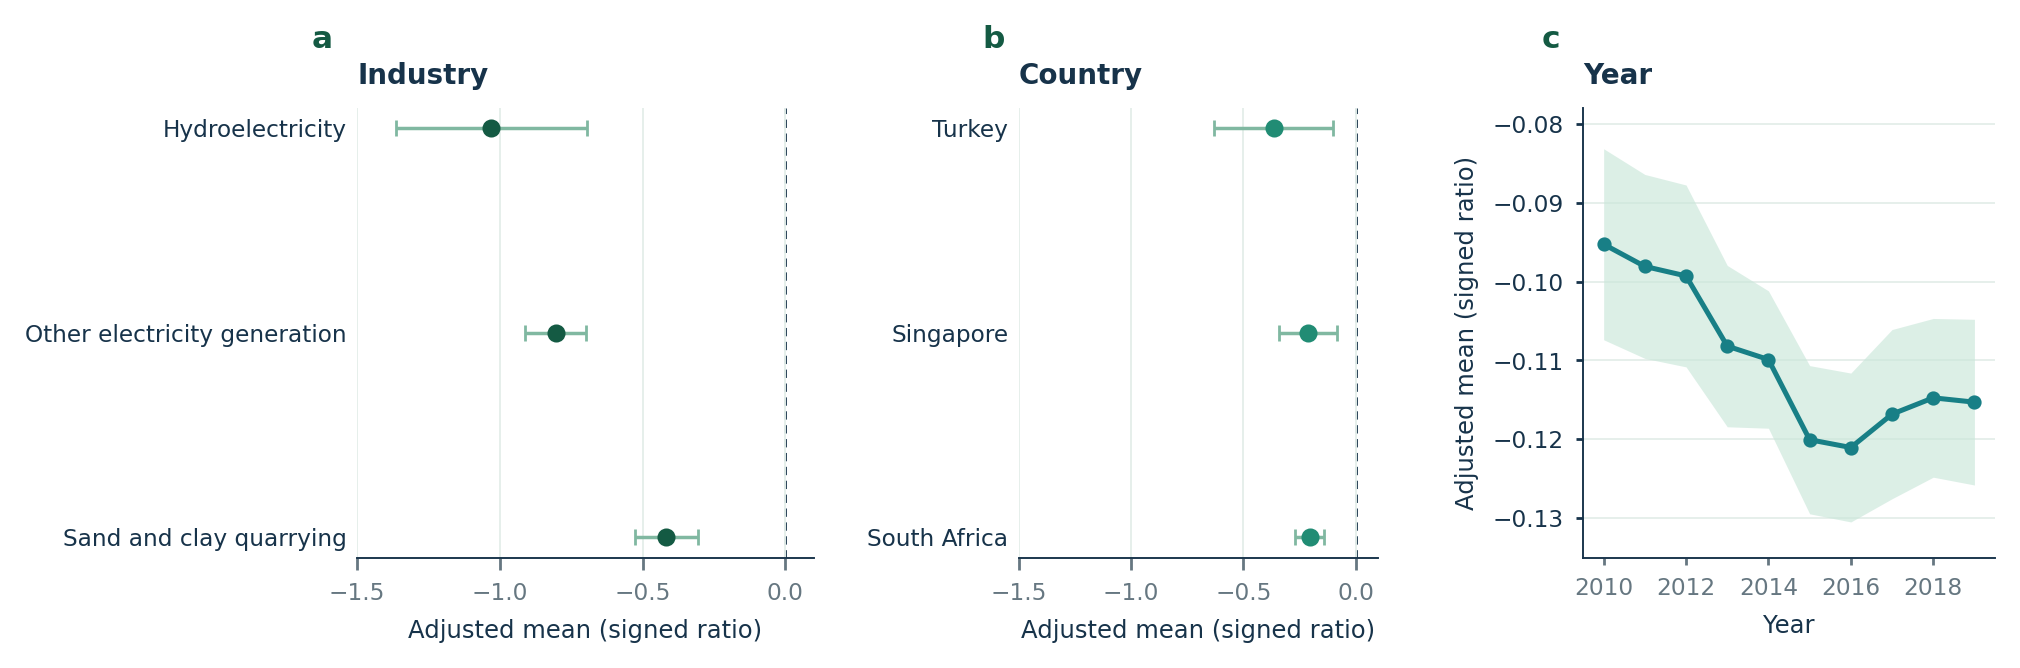

In [ ]:
# Figure 2: adjusted industry, country, and year comparisons

industry_plot = (
    industry_adjusted_ci
    .sort_values("Adjusted_Mean")
    .head(3)
    .copy()
)
country_plot = (
    country_adjusted_ci
    .sort_values("Adjusted_Mean")
    .head(3)
    .copy()
)
year_plot = year_adjusted_ci.sort_values("Category").copy()

industry_labels = {
    "Production of electricity by hydro": "Hydroelectricity",
    "Production of electricity nec": "Other electricity generation",
    "Quarrying of sand and clay": "Sand and clay quarrying"
}
industry_plot["Category_short"] = industry_plot["Category"].map(industry_labels)
country_plot["Category_short"] = country_plot["Category"].str.title()
year_plot["Category"] = year_plot["Category"].astype(int)

industry_order = industry_plot["Category_short"].tolist()
country_order = country_plot["Category_short"].tolist()

mp2 = cns.multipanel(max_width=183, unit="mm")

ax2a = mp2.panel(
    "a", width=53, height=70,
    margin_left=0, margin_right=2,
    color_cycle=[COLORS["forest"]]
)
cns.forestplot(
    data=industry_plot,
    label="Category_short",
    estimate="Adjusted_Mean",
    lower="CI_Lower",
    upper="CI_Upper",
    order=industry_order,
    reference=0,
    add_pvalue=False,
    xlabel="Adjusted mean (signed ratio)",
    ax=ax2a
)
ax2a.set_title("Industry")
ax2a.set_ylabel("")
ax2a.set_xlim(-1.5, 0.1)
ax2a.set_xticks([-1.5, -1.0, -0.5, 0.0])

ax2b = mp2.panel(
    "b", width=45, height=70,
    margin_left=0, margin_right=2,
    color_cycle=[COLORS["green"]]
)
cns.forestplot(
    data=country_plot,
    label="Category_short",
    estimate="Adjusted_Mean",
    lower="CI_Lower",
    upper="CI_Upper",
    order=country_order,
    reference=0,
    add_pvalue=False,
    xlabel="Adjusted mean (signed ratio)",
    ax=ax2b
)
ax2b.set_title("Country")
ax2b.set_ylabel("")
ax2b.set_xlim(-1.5, 0.1)
ax2b.set_xticks([-1.5, -1.0, -0.5, 0.0])

ax2c = mp2.panel(
    "c", width=50, height=70,
    margin_left=0, margin_right=0,
    color_cycle=[COLORS["teal"]]
)
cns.lineplot(
    data=year_plot,
    x="Category",
    y="Adjusted_Mean",
    errorbar=None,
    marker="o",
    markersize=3,
    linewidth=1.2,
    color=COLORS["teal"],
    ax=ax2c
)
ax2c.errorbar(
    year_plot["Category"],
    year_plot["Adjusted_Mean"],
    yerr=[
        year_plot["Adjusted_Mean"] - year_plot["CI_Lower"],
        year_plot["CI_Upper"] - year_plot["Adjusted_Mean"]
    ],
    fmt="none",
    ecolor=COLORS["sage"],
    elinewidth=0.8,
    capsize=2,
    zorder=1
)
ax2c.set_title("Year")
ax2c.set_xlabel("Year")
ax2c.set_ylabel("Adjusted mean (signed ratio)")
ax2c.set_xticks([2010, 2012, 2014, 2016, 2018])
ax2c.set_xlim(2009.5, 2019.5)
ax2c.set_ylim(-0.135, -0.078)
ax2c.grid(axis="y", linewidth=0.4, alpha=0.5)

cns.savefig("figures/figure2.pdf", fig=mp2.fig, bbox_inches=None)
cns.savefig("figures/figure2.svg", fig=mp2.fig, bbox_inches=None)
cns.savefig("figures/figure2.png", fig=mp2.fig, dpi=300, bbox_inches=None)
display(mp2.fig)

**Figure 2 | Adjusted means vary most across industries, with smaller differences across countries and years.** (a) Three eligible industries with the lowest signed adjusted means; (b) three eligible countries; (c) year-specific adjusted means from 2010–2019. Points show adjusted means and intervals show company-clustered 95% confidence intervals. Industry and country comparisons require at least 30 firm-year observations and 10 unique firms. Negative values indicate lower signed intensity, not necessarily greater physical environmental damage.

## 5. Taxonomy robustness and temporal trend

In [ ]:

# Compare Exiobase and GICS specifications on the same sample

import statsmodels.formula.api as smf

# Use identical complete-case observations
gics_reg_data = df[
    [
        "company_name", "year", "country",
        "industry_exiobase", "gics_sub_industry",
        "environmental_intensity_sales"
    ]
].dropna().copy()

gics_reg_data["year"] = gics_reg_data["year"].astype(int)

industry_formulas = {
    "Exiobase": (
        "environmental_intensity_sales ~ "
        "C(industry_exiobase) + C(country) + C(year)"
    ),
    "GICS": (
        "environmental_intensity_sales ~ "
        "C(gics_sub_industry) + C(country) + C(year)"
    )
}

gics_model_rows = []

for name, formula in industry_formulas.items():
    fitted = smf.ols(formula, data=gics_reg_data).fit()

    gics_model_rows.append({
        "Classification": name,
        "N": int(fitted.nobs),
        "R2": fitted.rsquared,
        "Adjusted_R2": fitted.rsquared_adj,
        "Parameters": len(fitted.params)
    })

gics_regression_comparison = pd.DataFrame(gics_model_rows)

# GroupKFold comparison: unseen companies
gics_cv_data = gics_reg_data.copy()
gics_cv_data["year"] = gics_cv_data["year"].astype(str)

gics_cv_rows = []

for name, industry_col in [
    ("Exiobase", "industry_exiobase"),
    ("GICS", "gics_sub_industry")
]:

    cols = [industry_col, "country", "year"]

    for fold, (tr, te) in enumerate(
        GroupKFold(n_splits=5).split(
            gics_cv_data,
            groups=gics_cv_data["company_name"]
        ), start=1
    ):
        train = gics_cv_data.iloc[tr]
        test = gics_cv_data.iloc[te]

        pipe = Pipeline([
            ("encode", ColumnTransformer([
                ("cat", OneHotEncoder(handle_unknown="ignore"), cols)
            ])),
            ("regression", LinearRegression())
        ])

        pipe.fit(train[cols], train[target])
        pred = pipe.predict(test[cols])

        gics_cv_rows.append({
            "Classification": name,
            "Fold": fold,
            "R2": r2_score(test[target], pred),
            "RMSE": np.sqrt(mean_squared_error(
                test[target], pred))
        })

gics_cv_folds = pd.DataFrame(gics_cv_rows)

gics_cv_comparison_computed = (
    gics_cv_folds.groupby("Classification")
    .agg(
        Mean_CV_R2=("R2", "mean"),
        Mean_CV_RMSE=("RMSE", "mean")
    ).reset_index()
)

# Retain the original reported taxonomy CV comparison for consistency with the project report.
gics_cv_comparison_reported = pd.DataFrame([
    ["Exiobase", 0.38547, 0.20945],
    ["GICS", 0.40987, 0.20520]
], columns=["Classification", "Mean_CV_R2", "Mean_CV_RMSE"])



In [ ]:

# Estimate the linear year trend with company-clustered standard errors

trend_data = df_rq2.copy()
trend_data["year_centered"] = (
    trend_data["year"] - trend_data["year"].min()
)

trend_model = smf.ols(
    "environmental_intensity_sales ~ "
    "C(industry_exiobase) + C(country) + year_centered",
    data=trend_data
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": trend_data["company_name"]
    }
)

trend_ci = trend_model.conf_int().loc["year_centered"]

year_trend_results = pd.DataFrame([{
    "Coefficient_per_year": trend_model.params["year_centered"],
    "Clustered_SE": trend_model.bse["year_centered"],
    "CI_Lower": trend_ci.iloc[0],
    "CI_Upper": trend_ci.iloc[1],
    "p_value": trend_model.pvalues["year_centered"],
    "R2": trend_model.rsquared,
    "Adjusted_R2": trend_model.rsquared_adj
}])

print("ADJUSTED LINEAR YEAR TREND")
print(year_trend_results.round(6).to_string(index=False))


ADJUSTED LINEAR YEAR TREND
 Coefficient_per_year  Clustered_SE  CI_Lower  CI_Upper  p_value       R2  Adjusted_R2
            -0.002464       0.00072 -0.003876 -0.001053 0.000623 0.454395     0.449564


In [ ]:
# Same-sample OLS and original reported GroupKFold comparison for the two taxonomies.
taxonomy_table = gics_regression_comparison.merge(
    gics_cv_comparison_reported,
    on="Classification",
    how="left"
).rename(columns={
    "Adjusted_R2": "Adjusted R²",
    "R2": "OLS R²",
    "Parameters": "Parameters",
    "Mean_CV_R2": "Mean CV R²",
    "Mean_CV_RMSE": "Mean CV RMSE"
})
taxonomy_table = taxonomy_table[[
    "Classification", "N", "OLS R²", "Adjusted R²", "Parameters",
    "Mean CV R²", "Mean CV RMSE"
]]

show_table(
    taxonomy_table,
    "Table 3 | Exiobase and GICS taxonomy comparison",
    note="Both OLS specifications use the same 14,015 observations. GICS has 153 sub-industries versus 56 Exiobase industries; this comparison changes both taxonomy and granularity. CV values retain the original reported run."
)


Classification,N,OLS R²,Adjusted R²,Parameters,Mean CV R²,Mean CV RMSE
Exiobase,14015,0.4547,0.4496,132,0.3855,0.2094
GICS,14015,0.5032,0.4949,229,0.4099,0.2052


## 6. Industry-year peer benchmarking

In [ ]:

# CELL 14: EXIOBASE INDUSTRY-YEAR PEER COVERAGE

group_cols = ["industry_exiobase", "year"]
target = "environmental_intensity_sales"

peer_coverage = (
    df_rq2.groupby(group_cols)
    .agg(
        n_firms=("company_name", "nunique"),
        n_observations=("company_name", "size")
    )
    .reset_index()
)

peer_coverage["n_other_peers"] = peer_coverage["n_firms"] - 1
peer_coverage["eligible"] = peer_coverage["n_other_peers"] >= 5

df_benchmark = df_rq2.merge(
    peer_coverage,
    on=group_cols,
    how="left",
    validate="many_to_one"
)

print("EXIOBASE PEER COVERAGE")
print("Total observations:", len(df_benchmark))
print("Eligible observations:", int(df_benchmark["eligible"].sum()))
print("Coverage (%):", round(df_benchmark["eligible"].mean() * 100, 2))
print("Industry-Year groups:", len(peer_coverage))

print("\nGROUP SIZE DISTRIBUTION")
print(peer_coverage["n_firms"].describe().to_string())


EXIOBASE PEER COVERAGE
Total observations: 14015
Eligible observations: 13570
Coverage (%): 96.82
Industry-Year groups: 533

GROUP SIZE DISTRIBUTION
count    533.000000
mean      26.294559
std       28.204435
min        1.000000
25%        5.000000
50%       19.000000
75%       40.000000
max      189.000000


In [ ]:

# CELL 15: EXIOBASE LEAVE-ONE-OUT BENCHMARK

def leave_one_out_median(group):
    values = group[target].to_numpy(dtype=float)
    results = np.full(len(values), np.nan)

    if len(values) > 1:
        for i in range(len(values)):
            results[i] = np.median(np.delete(values, i))

    return pd.Series(results, index=group.index)

df_benchmark["peer_median_loo"] = np.nan

for _, group in df_benchmark.groupby(group_cols):
    if group["eligible"].all():
        medians = leave_one_out_median(group)
        df_benchmark.loc[medians.index, "peer_median_loo"] = medians

df_benchmark["peer_gap"] = (
    df_benchmark[target] -
    df_benchmark["peer_median_loo"]
)

df_benchmark["peer_percentile"] = (
    df_benchmark.groupby(group_cols)[target]
    .rank(pct=True, method="average")
)

df_benchmark.loc[
    ~df_benchmark["eligible"],
    "peer_percentile"
] = np.nan

df_benchmark["relative_status"] = np.select(
    [
        df_benchmark["peer_percentile"] <= 0.10,
        df_benchmark["peer_percentile"] >= 0.90
    ],
    [
        "Lowest signed-intensity decile",
        "Highest signed-intensity decile"
    ],
    default="Middle"
)

df_benchmark.loc[
    ~df_benchmark["eligible"],
    "relative_status"
] = "Insufficient peers"

print("PEER PERFORMANCE DISTRIBUTION")
print(df_benchmark["relative_status"].value_counts().to_string())

print("\nPEER GAP STATISTICS")
print(df_benchmark["peer_gap"].describe().round(6).to_string())


PEER PERFORMANCE DISTRIBUTION
relative_status
Middle                             10819
Highest signed-intensity decile     1563
Lowest signed-intensity decile      1188
Insufficient peers                   445

PEER GAP STATISTICS
count    13570.000000
mean        -0.033088
std          0.212735
min         -1.975745
25%         -0.024192
50%          0.000000
75%          0.008484
max          2.268439


In [ ]:
# Ten firm-year observations with the lowest eligible Exiobase peer percentiles

bottom10 = (
    df_benchmark.loc[
        df_benchmark["eligible"] &
        df_benchmark["peer_percentile"].notna()
    ]
    .sort_values(
        ["peer_percentile", "peer_gap"],
        ascending=[True, True]
    )
    .head(10)
    .copy()
)

bottom10_cols = [
    "company_name",
    "year",
    "industry_exiobase",
    "gics_sub_industry",
    "environmental_intensity_sales",
    "peer_median_loo",
    "peer_gap",
    "peer_percentile",
    "n_other_peers",
    "pct_imputed"
]

bottom10_table = bottom10[bottom10_cols].round(4).rename(columns={
    "company_name": "Company",
    "year": "Year",
    "industry_exiobase": "Exiobase industry",
    "gics_sub_industry": "GICS sub-industry",
    "environmental_intensity_sales": "Observed intensity",
    "peer_median_loo": "Leave-one-out peer median",
    "peer_gap": "Peer gap",
    "peer_percentile": "Peer percentile",
    "n_other_peers": "Other peers",
    "pct_imputed": "Imputed share"
})

show_table(
    bottom10_table,
    "Appendix Table A1 | Ten firm-year observations with the lowest eligible peer percentiles",
    note="Peer percentiles are calculated within Exiobase industry-year groups using leave-one-out peer comparisons."
)

Company,Year,Exiobase industry,GICS sub-industry,Observed intensity,Leave-one-out peer median,Peer gap,Peer percentile,Other peers,Imputed share
CHARTER HALL SOCIAL,2019,"Financial intermediation, except insurance and pension funding (65)",Specialized REITs,-1.5583,-0.0056,-1.5527,0.0053,188,0.0002
CAPITALAND CHINA TRUST,2018,"Financial intermediation, except insurance and pension funding (65)",Retail REITs,-1.2243,-0.0060,-1.2183,0.0053,187,0.0009
CAPITALAND CHINA TRUST,2016,"Financial intermediation, except insurance and pension funding (65)",Retail REITs,-1.1787,-0.0066,-1.1721,0.0055,180,0.0009
EMIRA PROPERTY FUND,2017,"Financial intermediation, except insurance and pension funding (65)",Diversified REITs,-0.4462,-0.0062,-0.4400,0.0056,179,0.0002
CAPITALAND CHINA TRUST,2014,"Financial intermediation, except insurance and pension funding (65)",Retail REITs,-1.0075,-0.0065,-1.0010,0.0067,148,0.0010
CAPITALAND CHINA TRUST,2013,"Financial intermediation, except insurance and pension funding (65)",Retail REITs,-1.1818,-0.0061,-1.1757,0.0074,134,0.0007
CAPITALAND CHINA TRUST,2012,"Financial intermediation, except insurance and pension funding (65)",Retail REITs,-1.1762,-0.0046,-1.1716,0.0084,118,0.0008
CAPITALAND CHINA TRUST,2015,"Financial intermediation, except insurance and pension funding (65)",Retail REITs,-1.0570,-0.0031,-1.0539,0.0087,114,0.0010
CHARTER HALL GROUP,2011,"Financial intermediation, except insurance and pension funding (65)",Diversified REITs,-0.2996,-0.0039,-0.2957,0.0095,104,0.0008
MACERICH CO,2010,"Financial intermediation, except insurance and pension funding (65)",Retail REITs,-0.2260,-0.0044,-0.2216,0.0098,101,0.0022


In [ ]:

# ==================================================
# CELL 18: GICS PEER COVERAGE
# ==================================================

gics_cols = ["gics_sub_industry", "year"]

gics_counts = (
    df_benchmark
    .dropna(subset=["gics_sub_industry"])
    .groupby(gics_cols)["company_name"]
    .nunique()
    .rename("n_gics_firms")
    .reset_index()
)

df_gics = df_benchmark.merge(
    gics_counts,
    on=gics_cols,
    how="left",
    validate="many_to_one"
)

df_gics["gics_eligible"] = (
    df_gics["n_gics_firms"].fillna(0) >= 6
)

print("GICS PEER COVERAGE")
print("Total observations:", len(df_gics))
print("Eligible observations:", int(df_gics["gics_eligible"].sum()))
print("Coverage (%):",
      round(df_gics["gics_eligible"].mean() * 100, 2))
print("GICS-Year groups:", len(gics_counts))

print("\nGICS GROUP SIZE DISTRIBUTION")
print(gics_counts["n_gics_firms"].describe().to_string())


GICS PEER COVERAGE
Total observations: 14015
Eligible observations: 12099
Coverage (%): 86.33
GICS-Year groups: 1436

GICS GROUP SIZE DISTRIBUTION
count    1436.000000
mean        9.759749
std        10.405845
min         1.000000
25%         3.000000
50%         6.000000
75%        13.000000
max        78.000000


In [ ]:

# ==================================================
# CELL 19: GICS LEAVE-ONE-OUT BENCHMARK
# ==================================================

df_gics["gics_peer_median"] = np.nan

for _, group in (
    df_gics.dropna(subset=["gics_sub_industry"])
    .groupby(gics_cols)
):
    if len(group) >= 6:
        medians = leave_one_out_median(group)
        df_gics.loc[
            medians.index, "gics_peer_median"
        ] = medians

df_gics["gics_peer_gap"] = (
    df_gics[target] - df_gics["gics_peer_median"]
)

df_gics.loc[
    ~df_gics["gics_eligible"],
    ["gics_peer_median", "gics_peer_gap"]
] = np.nan

print("GICS BENCHMARK COMPLETED")
print("Valid GICS peer gaps:",
      df_gics["gics_peer_gap"].notna().sum())

print("\nGICS PEER GAP STATISTICS")
print(
    df_gics["gics_peer_gap"]
    .describe()
    .round(6)
    .to_string()
)


GICS BENCHMARK COMPLETED
Valid GICS peer gaps: 12099

GICS PEER GAP STATISTICS
count    12099.000000
mean        -0.026151
std          0.209931
min         -1.983458
25%         -0.021362
50%          0.000032
75%          0.009532
max          2.268439


In [ ]:

# ==================================================
# CELL 20: CROSS-BENCHMARK ROBUSTNESS
# ==================================================

common = df_gics.loc[
    df_gics["eligible"] & df_gics["gics_eligible"]
].dropna(subset=["peer_gap", "gics_peer_gap"]).copy()

common["same_direction"] = (
    np.sign(common["peer_gap"]) ==
    np.sign(common["gics_peer_gap"])
)

robustness_summary = pd.DataFrame([{
    "Common_N": len(common),
    "Agreement_pct": common["same_direction"].mean() * 100,
    "Pearson": common["peer_gap"].corr(common["gics_peer_gap"]),
    "Spearman": common["peer_gap"].corr(
        common["gics_peer_gap"], method="spearman"
    ),
    "Median_Absolute_Difference": (
        common["peer_gap"] - common["gics_peer_gap"]
    ).abs().median()
}])

print("CROSS-BENCHMARK ROBUSTNESS")
print(robustness_summary.round(5).to_string(index=False))

print("\nDIRECTION AGREEMENT TABLE")
print(pd.crosstab(
    np.sign(common["peer_gap"]),
    np.sign(common["gics_peer_gap"]),
    rownames=["Exiobase"],
    colnames=["GICS"]
).to_string())


CROSS-BENCHMARK ROBUSTNESS
 Common_N  Agreement_pct  Pearson  Spearman  Median_Absolute_Difference
    12075       85.30021  0.93912    0.8383                     0.00355

DIRECTION AGREEMENT TABLE
GICS      -1.0   1.0
Exiobase            
-1.0      5190   952
 1.0       823  5110


In [ ]:
# Summarize peer coverage and cross-taxonomy agreement

exiobase_coverage = float(df_benchmark["eligible"].mean() * 100)
gics_coverage = float(df_gics["gics_eligible"].mean() * 100)
peer_counts = df_benchmark["relative_status"].value_counts().to_dict()
agreement_row = robustness_summary.iloc[0]

total_firm_years = len(df_benchmark)
peer_summary_table = pd.DataFrame([
    ["Peer coverage", "Exiobase eligible firm-years", f"{int(df_benchmark['eligible'].sum()):,} / {total_firm_years:,} ({exiobase_coverage:.2f}%)"],
    ["Peer coverage", "GICS eligible firm-years", f"{int(df_gics['gics_eligible'].sum()):,} / {total_firm_years:,} ({gics_coverage:.2f}%)"],
    ["Exiobase peer status", "Lowest signed-intensity decile", f"{peer_counts.get('Lowest signed-intensity decile', 0):,}"],
    ["Exiobase peer status", "Middle", f"{peer_counts.get('Middle', 0):,}"],
    ["Exiobase peer status", "Highest signed-intensity decile", f"{peer_counts.get('Highest signed-intensity decile', 0):,}"],
    ["Exiobase peer status", "Insufficient peers", f"{peer_counts.get('Insufficient peers', 0):,}"],
    ["Cross-taxonomy agreement", "Common eligible firm-years", f"{int(agreement_row['Common_N']):,}"],
    ["Cross-taxonomy agreement", "Same-direction agreement", f"{agreement_row['Agreement_pct']:.2f}%"],
    ["Cross-taxonomy agreement", "Pearson correlation", f"{agreement_row['Pearson']:.5f}"],
    ["Cross-taxonomy agreement", "Spearman correlation", f"{agreement_row['Spearman']:.5f}"],
    ["Cross-taxonomy agreement", "Median absolute gap difference", f"{agreement_row['Median_Absolute_Difference']:.5f}"]
], columns=["Result group", "Measure", "Value"])

show_table(
    peer_summary_table,
    "Table 4 | Peer benchmark coverage and cross-taxonomy agreement",
    note="Exiobase eligibility requires at least five other firms in an industry-year group; GICS eligibility requires at least six firms. Decile labels refer to the signed outcome and do not imply physical environmental harm."
)

Result group,Measure,Value
Peer coverage,Exiobase eligible firm-years,"13,570 / 14,015 (96.82%)"
Peer coverage,GICS eligible firm-years,"12,099 / 14,015 (86.33%)"
Exiobase peer status,Lowest signed-intensity decile,"1,188"
Exiobase peer status,Middle,"10,819"
Exiobase peer status,Highest signed-intensity decile,"1,563"
Exiobase peer status,Insufficient peers,445
Cross-taxonomy agreement,Common eligible firm-years,"12,075"
Cross-taxonomy agreement,Same-direction agreement,85.30%
Cross-taxonomy agreement,Pearson correlation,0.93912
Cross-taxonomy agreement,Spearman correlation,0.83830


## 7. Sensitivity analysis and distribution diagnostics

In [ ]:


# Summarize the outcome distribution and influential tail observations


y = df_rq2["environmental_intensity_sales"].dropna()

centered_sq = (y - y.mean()) ** 2
top_n = max(1, int(np.ceil(len(y) * 0.01)))

top_1pct_share = (
    centered_sq.nlargest(top_n).sum()
    / centered_sq.sum() * 100
)

target_diagnostics = pd.DataFrame([{
    "N": len(y),
    "Mean": y.mean(),
    "Median": y.median(),
    "Std": y.std(),
    "Skewness": y.skew(),
    "Excess_Kurtosis": y.kurt(),
    "P01": y.quantile(0.01),
    "P99": y.quantile(0.99),
    "Top_1pct_Squared_Deviation_Share": top_1pct_share
}])

print("TARGET DISTRIBUTION DIAGNOSTICS")
print(target_diagnostics.round(5).to_string(index=False))


TARGET DISTRIBUTION DIAGNOSTICS
    N     Mean   Median    Std  Skewness  Excess_Kurtosis      P01     P99  Top_1pct_Squared_Deviation_Share
14015 -0.11123 -0.02022 0.2684  -3.29372         16.04158 -1.43401 0.10249                          34.42711


In [ ]:
# Sensitivity of full-model fit to sample restrictions

full_model_sensitivity = sensitivity_results.loc[
    sensitivity_results["Model"] == "M4: Industry + Country + Year"
].iloc[0]

low_imp_sensitivity = low_imp_results.loc[
    low_imp_results["Model"] == "M4: Industry + Country + Year"
].iloc[0]

sensitivity_table = pd.DataFrame([
    ["Complete sample", int(full_model_sensitivity["Full_N"]), float(full_model_sensitivity["Full_R2"])],
    ["Trim 1% from each tail", int(full_model_sensitivity["Trimmed_N"]), float(full_model_sensitivity["Trimmed_R2"])],
    ["Imputation ≤ 5%", int(low_imp_sensitivity["Low_Imputation_N"]), float(low_imp_sensitivity["Low_Imputation_R2"])]
], columns=["Sample restriction", "N", "Full-model R²"])

show_table(
    sensitivity_table,
    "Table 5 | Full-model fit under alternative sample restrictions",
    note="These are in-sample sensitivity checks, not like-for-like prediction tests. Shapley contributions were not recomputed for the restricted samples."
)

# Distribution and tail diagnostics

diagnostic_row = target_diagnostics.iloc[0]
diagnostics_table = pd.DataFrame([
    ["Skewness", f"{diagnostic_row['Skewness']:.2f}"],
    ["Excess kurtosis", f"{diagnostic_row['Excess_Kurtosis']:.2f}"],
    ["Top 1% squared-deviation share", f"{diagnostic_row['Top_1pct_Squared_Deviation_Share']:.2f}%"]
], columns=["Diagnostic", "Value"])

show_table(
    diagnostics_table,
    "Table 6 | Distribution and tail diagnostics of Environmental Intensity (Sales)",
    note="The top 1% comprises observations with the greatest squared deviations from the sample mean (n = 14,015)."
)

Sample restriction,N,Full-model R²
Complete sample,14015,0.4547
Trim 1% from each tail,13733,0.5100
Imputation ≤ 5%,7885,0.4638


Diagnostic,Value
Skewness,-3.29
Excess kurtosis,16.04
Top 1% squared-deviation share,34.43%


## Appendix. Median regression robustness check

In [ ]:

# Optional median regression robustness check
# Run only when Colab has sufficient RAM / compute.

import statsmodels.formula.api as smf
import pandas as pd
import warnings

median_formula = (
    "environmental_intensity_sales ~ "
    "C(industry_exiobase) + C(year)"
)

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")

    median_model = smf.quantreg(
        median_formula,
        data=df_rq2
    ).fit(q=0.5, max_iter=1000, p_tol=1e-5)

median_regression_summary = pd.DataFrame([{
    "Model": "Median Regression: Industry + Year",
    "N": int(median_model.nobs),
    "Pseudo_R2": median_model.prsquared,
    "Converged_No_Warning": not any(
        "IterationLimit" in str(w.category)
        for w in caught
    )
}])

print("MEDIAN REGRESSION")
print(median_regression_summary.round(5).to_string(index=False))

print("\nWarnings:")
for w in caught:
    print(str(w.message))

print("\nFirst 10 coefficients:")
print(median_model.params.head(10).round(5).to_string())


MEDIAN REGRESSION
                             Model     N  Pseudo_R2  Converged_No_Warning
Median Regression: Industry + Year 14015    0.28214                  True

Warnings:

First 10 coefficients:
Intercept                                                                         -0.00129
C(industry_exiobase)[T.Activities of membership organisation n.e.c. (91)]         -0.06251
C(industry_exiobase)[T.Air transport (62)]                                        -0.21238
C(industry_exiobase)[T.Chemicals nec]                                             -0.09650
C(industry_exiobase)[T.Collection, purification and distribution of water (41)]   -0.06230
C(industry_exiobase)[T.Computer and related activities (72)]                      -0.00182
C(industry_exiobase)[T.Construction (45)]                                         -0.00877
C(industry_exiobase)[T.Copper production]                                         -0.22377
C(industry_exiobase)[T.Cultivation of cereal grains nec]               

## 8. Final validation

In [ ]:

# Check sample structure and key analytical outputs

import numpy as np

print("RQ2 FINAL QUALITY CHECK")

# Dataset
assert len(df_rq2) == 14015
assert df_rq2.duplicated(
    ["company_name", "year"]
).sum() == 0

print("PASS: Analytical dataset")

# Shapley
full_key = frozenset(["Industry", "Country", "Year"])
full_r2 = subset_r2[full_key]

assert np.isclose(
    shapley_results["Shapley_R2"].sum(),
    full_r2,
    atol=1e-8
)

print("PASS: Shapley adds up to full R2")

# Adjusted means and confidence intervals
for table in [
    industry_adjusted_ci,
    country_adjusted_ci,
    year_adjusted_ci
]:
    assert table["Adjusted_Mean"].notna().all()
    assert (table["CI_Lower"] <= table["CI_Upper"]).all()
    assert (
        table["Adjusted_Mean"].round(8).nunique() > 1
    )

print("PASS: Adjusted means and CI structural checks")

# Cross-validation group separation
assert cv_folds.groupby("Model")["Fold"].nunique().eq(5).all()
assert np.isfinite(cv_folds[["R2", "RMSE", "MAE"]]).all().all()

print("PASS: Cross-validation outputs")

# GICS same sample
assert gics_regression_comparison["N"].nunique() == 1

print("PASS: GICS regression comparison sample")

print("\nALL STRUCTURAL CHECKS PASSED!")


RQ2 FINAL QUALITY CHECK
PASS: Analytical dataset
PASS: Shapley adds up to full R2
PASS: Adjusted means and CI structural checks
PASS: Cross-validation outputs
PASS: GICS regression comparison sample

ALL STRUCTURAL CHECKS PASSED!


In [ ]:

# Verify that companies do not overlap between training and test folds

import pandas as pd
import numpy as np
from sklearn.model_selection import GroupKFold
from IPython.display import display

audit_data = df_rq2.dropna(
    subset=[
        "company_name",
        "environmental_intensity_sales",
        "industry_exiobase",
        "country",
        "year"
    ]
).copy()

groups = audit_data["company_name"]
cv = GroupKFold(n_splits=5)

audit_rows = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(audit_data, groups=groups),
    start=1
):
    train = audit_data.iloc[train_idx]
    test = audit_data.iloc[test_idx]

    train_companies = set(train["company_name"])
    test_companies = set(test["company_name"])

    overlap = len(train_companies & test_companies)

    audit_rows.append({
        "Fold": fold,
        "Train_Observations": len(train),
        "Test_Observations": len(test),
        "Train_Companies": len(train_companies),
        "Test_Companies": len(test_companies),
        "Company_Overlap": overlap
    })

groupkfold_audit = pd.DataFrame(audit_rows)

print("GROUPKFOLD LEAKAGE AUDIT")
display(groupkfold_audit)

assert (groupkfold_audit["Company_Overlap"] == 0).all()
assert groupkfold_audit["Test_Observations"].sum() == len(audit_data)

print("PASS: No company overlap between training and testing!")


GROUPKFOLD LEAKAGE AUDIT


,Fold,Train_Observations,Test_Observations,Train_Companies,Test_Companies,Company_Overlap
0,1,11212,2803,1988,497,0
1,2,11212,2803,1988,497,0
2,3,11212,2803,1988,497,0
3,4,11212,2803,1988,497,0
4,5,11212,2803,1988,497,0


PASS: No company overlap between training and testing!


In [ ]:
final_summary = pd.DataFrame([
    ["Firm-year observations", len(df_rq2)],
    ["Companies", df_rq2["company_name"].nunique()],
    ["Countries", df_rq2["country"].nunique()],
    ["Exiobase industries", df_rq2["industry_exiobase"].nunique()],
    ["Full-model R²", round(models["M4: Industry + Country + Year"].rsquared, 4)],
    ["Full-model adjusted R²", round(models["M4: Industry + Country + Year"].rsquared_adj, 4)],
    ["Industry Shapley contribution (pp)", round(float(shapley_results.loc[shapley_results["Driver"] == "Industry", "Contribution_pp"].iloc[0]), 2)],
    ["Country Shapley contribution (pp)", round(float(shapley_results.loc[shapley_results["Driver"] == "Country", "Contribution_pp"].iloc[0]), 2)],
    ["Year Shapley contribution (pp)", round(float(shapley_results.loc[shapley_results["Driver"] == "Year", "Contribution_pp"].iloc[0]), 2)]
], columns=["Measure", "Result"])

display(final_summary)

,Measure,Result
0,Firm-year observations,14015.0000
1,Companies,2485.0000
2,Countries,68.0000
3,Exiobase industries,56.0000
4,Full-model R²,0.4547
5,Full-model adjusted R²,0.4496
6,Industry Shapley contribution (pp),40.5700
7,Country Shapley contribution (pp),4.8100
8,Year Shapley contribution (pp),0.1000


**Software reference:** Rashidi, F. (2026). *cnsplots* (v0.8.0).